# 02 · Production: cleaning, unit compatibility and validation
Production can only be multiplied by a price if both refer to the **same commodity form and unit**. This notebook builds the production layer (`src/build_production.py`) and checks the units first.

| | |
|---|---|
| **Objective** | Clean district production and put every crop in the unit MSP is quoted in. |
| **Dataset** | DES APY district x crop x season, 1997-2019. |
| **Business question** | How much is produced, and in what unit can it be multiplied by MSP? |
| **Method** | Name harmonisation, duplicate/outlier removal, unit conversion (milled rice -> paddy, lint -> kapas, tonnes -> quintals). |
| **Output** | fact_production, dimension tables, national production chart. |
| **Key finding** | Converting units changes rice value by x1.49 and cotton by x2.9 compared with naive multiplication. |

In [1]:
import sys, sqlite3, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import RAW, CURATED, PROC, RESULTS, FIGURES, DB_PATH, connect_ro
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
BLUE, ORANGE, AQUA, YELLOW, PINK, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#e34948", "#9aa19c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 11})
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight"); plt.show()
from src import build_production

## 1. Unit check: is APY rice reported as paddy or milled rice?
Paddy yields in Punjab are about 6 t/ha; milled rice about 4 t/ha.

In [2]:
apy = pd.read_csv(RAW / "apy_district_1997_2019.csv")
p = apy[(apy.state == "Punjab") & apy.crop.isin(["Rice", "Wheat", "Cotton(Lint)"])].groupby(["crop", "year"])[["area", "production"]].sum()
p["yield_per_ha"] = p.production / p.area
p.loc[(slice(None), [2005, 2010, 2015]), :].round(2)

area  production  yield_per_ha
crop         year                                     
Cotton(Lint) 2005   557000.0     2395000          4.30
             2010   483000.0     1822000          3.77
             2015   339000.0      393000          1.16
Rice         2005  2642000.0    10193000          3.86
             2010  2831000.0    10837000          3.83
             2015  2518000.0     9618000          3.82
Wheat        2005  3468000.0    14493000          4.18
             2010  3510000.0    16472000          4.69
             2015  3508000.0    16077000          4.58

Punjab rice at about 3.9 t/ha means **milled rice**, while the MSP is for **paddy**. Cotton is in **bales of 170 kg lint**, while the MSP is for **kapas** (seed cotton). Both need converting before valuation.

## 2. The conversion table (`dim_crop`)

In [3]:
summary = build_production.main()
dim_crop = pd.read_csv(PROC / "dim_crop.csv")
dim_crop[["crop_name", "crop_group", "apy_unit", "price_form", "to_price_qtl_factor", "is_msp_crop"]]

{'raw_rows_all_crops': 326846, 'rows_analysed_crops': 240102, 'fact_rows': 239760, 'excluded_rows': 342, 'districts': 760, 'states': 36}
issue
Crop year 2020 present for only a handful of districts             219
Duplicate district-crop-year-season key with conflicting values    114
Implausible yield (above agronomic ceiling for crop)                 9
dtype: int64


,crop_name,crop_group,apy_unit,price_form,to_price_qtl_factor,is_msp_crop
0,Rice,Cereals,tonnes (milled rice),"Paddy (common), Rs/qtl",14.925373,True
1,Wheat,Cereals,tonnes,Wheat grain,10.000000,True
2,Maize,Cereals,tonnes,Maize grain,10.000000,True
3,Jowar,Coarse cereals,tonnes,Jowar hybrid,10.000000,True
4,Bajra,Coarse cereals,tonnes,Bajra,10.000000,True
5,Ragi,Coarse cereals,tonnes,Ragi,10.000000,True
6,Barley,Coarse cereals,tonnes,Barley,10.000000,True
7,Gram,Pulses,tonnes,Gram (whole),10.000000,True
8,Arhar/Tur,Pulses,tonnes,Tur (whole),10.000000,True
9,Moong,Pulses,tonnes,Moong (whole),10.000000,True


- Rice: 1 t milled rice → 10 ÷ 0.67 = **14.93 qtl paddy** (FCI out-turn ratio 67%)
- Cotton: 1 lint bale (170 kg) → 1.7 ÷ 0.34 = **5.0 qtl kapas** (34% ginning out-turn, an assumption with a 33–36% typical range)
- Jute: 1 bale = 1.8 qtl. All other crops: 1 t = 10 qtl.

## 3. What was removed and why

In [4]:
dq = pd.read_csv(PROC / "dq_production_issues.csv")
display(dq.groupby(["issue", "action"]).size().rename("rows").reset_index())
dq[dq.issue.str.startswith("Duplicate")].head(6)

,issue,action,rows
0,Crop year 2020 present for only a handful of d...,excluded,219
1,Duplicate district-crop-year-season key with c...,excluded (both rows),114
2,Implausible yield (above agronomic ceiling for...,excluded,9


,state,district,crop,year,season,area,production,issue,action
219,West Bengal,Paraganas North,Cotton(Lint),2001,Kharif,250.0,620,Duplicate district-crop-year-season key with c...,excluded (both rows)
220,West Bengal,Paraganas North,Cotton(Lint),2002,Kharif,15.0,60,Duplicate district-crop-year-season key with c...,excluded (both rows)
221,West Bengal,Paraganas North,Cotton(Lint),2003,Kharif,133.0,439,Duplicate district-crop-year-season key with c...,excluded (both rows)
222,West Bengal,Paraganas North,Cotton(Lint),2005,Kharif,137.0,445,Duplicate district-crop-year-season key with c...,excluded (both rows)
223,West Bengal,Paraganas North,Cotton(Lint),2006,Kharif,137.0,445,Duplicate district-crop-year-season key with c...,excluded (both rows)
224,West Bengal,Paraganas North,Cotton(Lint),2007,Kharif,2980.0,834,Duplicate district-crop-year-season key with c...,excluded (both rows)


## 4. National production trend (sum of districts)

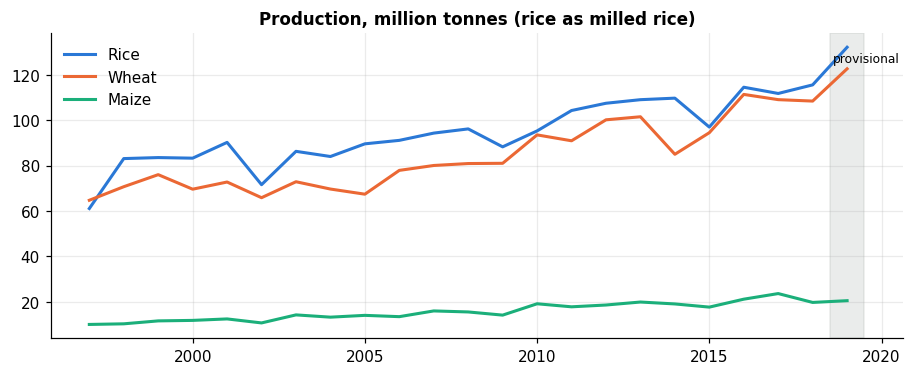

In [5]:
fact = pd.read_csv(PROC / "fact_production.csv").merge(dim_crop[["crop_id", "crop_name"]], on="crop_id")
nat = fact.groupby(["crop_name", "crop_year"]).production_apy_unit.sum().unstack(0) / 1e6
fig, ax = plt.subplots(figsize=(10, 3.6))
for c, col in [("Rice", BLUE), ("Wheat", ORANGE), ("Maize", AQUA)]:
    ax.plot(nat.index, nat[c], color=col, lw=2, label=c)
ax.axvspan(2018.5, 2019.5, color=GREY, alpha=.2); ax.text(2018.6, nat["Rice"].max() * .95, "provisional", fontsize=8)
ax.set_title("Production, million tonnes (rice as milled rice)"); ax.legend(frameon=False)
save(fig, "02_national_production")

## 5. Validation against official DES estimates (PIB, 3rd Advance Estimates 2019-20)

In [6]:
official = {"Rice": 117.94, "Wheat": 107.18, "Maize": 28.98, "Gram": 10.90, "Soyabean": 12.24,
            "Rapeseed & Mustard": 8.70, "Sugarcane": 358.14, "Cotton": 36.05}
v = pd.DataFrame({"district_sum": nat.loc[2019, list(official)], "DES_estimate": pd.Series(official)})
v["diff_%"] = (v.district_sum / v.DES_estimate - 1) * 100
v.round(1)

,district_sum,DES_estimate,diff_%
Rice,132.1,117.9,12.0
Wheat,122.6,107.2,14.4
Maize,20.5,29.0,-29.3
Gram,10.1,10.9,-7.1
Soyabean,10.2,12.2,-16.7
Rapeseed & Mustard,8.5,8.7,-1.9
Sugarcane,367.2,358.1,2.5
Cotton,33.2,36.0,-8.0


**Takeaways**
- Unit conversion matters: without it, rice would be undervalued by about 33% and cotton by about 66%.
- District sums diverge from DES estimates in 2019-20 (rice +12%, wheat +14%, maize −29%), so **2019 is flagged provisional** and excluded from headline windows. Maize is under-captured in most years.

## Conclusion
Production is clean and in MSP-compatible units.

## Limitations
District totals diverge from DES estimates in the provisional year 2019-20; horticulture largely missing after 2003.

## Next steps
Add DES production for 2020-21 onward.